# Análise de dados


In [48]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

path = "https://raw.githubusercontent.com/squad-ada-lovelace/Desafio_07-Desafio-final/refs/heads/claudia/processed/qualidade_do_sono_tratado.csv"
df = pd.read_csv(path)
df.head()

,ID da pessoa,genero,idade,ocupacao,qualidade do sono,tempo diario de atividade fisica,nivel de estresse,classificacao do IMC,batimentos cardiacos,passos diarios,transtorno do sono,duracao do sono (min),pressao sistolica,pressao diastolica,categoria qualidade do sono,classificacao pressao
0,1,masculino,27,engenheiro(a) de software,6,42,6,sobrepeso,77,4200,sem transtorno,366.0,126,83,moderada,pré-hipertensão
1,2,masculino,28,medico(a),6,60,8,peso normal,75,10000,sem transtorno,372.0,125,80,moderada,normal
2,3,masculino,28,medico(a),6,60,8,peso normal,75,10000,sem transtorno,372.0,125,80,moderada,normal
3,4,masculino,28,representante de vendas,4,30,8,obesidade,85,3000,com transtorno,354.0,140,90,ruim,hipertensão estágio 1
4,5,masculino,28,representante de vendas,4,30,8,obesidade,85,3000,com transtorno,354.0,140,90,ruim,hipertensão estágio 1


In [49]:
df.columns

Index(['ID da pessoa', 'genero', 'idade', 'ocupacao', 'qualidade do sono',
       'tempo diario de atividade fisica', 'nivel de estresse',
       'classificacao do IMC', 'batimentos cardiacos', 'passos diarios',
       'transtorno do sono', 'duracao do sono (min)', 'pressao sistolica',
       'pressao diastolica', 'categoria qualidade do sono',
       'classificacao pressao'],
      dtype='str')

In [50]:
# Tratamento da variável "ocupação" para substituir ocorrências de profissões menores que 10 pelo termo "outros"
contagem = df["ocupacao"].value_counts()
raras = contagem[contagem < 10].index

df["ocupacao"] = df["ocupacao"].replace(raras, "Outros")

In [51]:
# Tirando colunas que podem gerar vazamento ou ruído
df = df.drop(columns=['ID da pessoa', 'qualidade do sono', 'duracao do sono (min)', 'pressao sistolica', 'pressao diastolica'])


- Depois de retirar as colunas acima, o dataset começa a apresentar duplicatas, mas isso pode se dar tanto porque dados foram feitos de forma sintética e repetidos para atingir certo número ou porque sem identificação única, alguns perfis se tornam semelhantes (dois vendedores que tenham qualidade de sono boa, por exemplo, se tornam uma duplicada)

In [52]:
df.duplicated().sum()

np.int64(282)

In [53]:
# Dividindo em treino e teste
y = df['categoria qualidade do sono']
X = df.drop(columns='categoria qualidade do sono')

In [54]:
y.value_counts()

categoria qualidade do sono
boa         257
moderada    112
ruim          5
Name: count, dtype: int64

In [55]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size = 0.2,
    stratify = y,
    random_state=42
)

In [56]:
# Pré-processamento do dataframe
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 2. Separar colunas por tipo
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()
num_cols = X_train.select_dtypes(include="number").columns.tolist()

print("Categóricas:", cat_cols)
print("Numéricas:", num_cols)

# 3. Pré-processador
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False), cat_cols),
    ],
    verbose_feature_names_out=False,
)
preprocessor.set_output(transform="pandas")

# 4. fit só no treino; transform nos dois
X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc = preprocessor.transform(X_test)

# 5. Conferir o resultado
print(X_train_proc.shape, X_test_proc.shape)
print(X_train_proc.columns.tolist())
print(X_train_proc.isna().sum().sum())  # deve ser 0
X_train_proc.head()

Categóricas: ['genero', 'ocupacao', 'classificacao do IMC', 'transtorno do sono', 'classificacao pressao']
Numéricas: ['idade', 'tempo diario de atividade fisica', 'nivel de estresse', 'batimentos cardiacos', 'passos diarios']
(299, 21) (75, 21)
['idade', 'tempo diario de atividade fisica', 'nivel de estresse', 'batimentos cardiacos', 'passos diarios', 'genero_masculino', 'ocupacao_Outros', 'ocupacao_advogado(a)', 'ocupacao_contador(a)', 'ocupacao_enfermeiro(a)', 'ocupacao_engenheiro(a)', 'ocupacao_medico(a)', 'ocupacao_professor(a)', 'ocupacao_vendedor(a)', 'classificacao do IMC_obesidade', 'classificacao do IMC_peso normal', 'classificacao do IMC_sobrepeso', 'transtorno do sono_sem transtorno', 'classificacao pressao_hipertensão estágio 1', 'classificacao pressao_normal', 'classificacao pressao_pré-hipertensão']
0


,idade,tempo diario de atividade fisica,nivel de estresse,batimentos cardiacos,passos diarios,genero_masculino,ocupacao_Outros,ocupacao_advogado(a),ocupacao_contador(a),ocupacao_enfermeiro(a),...,ocupacao_medico(a),ocupacao_professor(a),ocupacao_vendedor(a),classificacao do IMC_obesidade,classificacao do IMC_peso normal,classificacao do IMC_sobrepeso,transtorno do sono_sem transtorno,classificacao pressao_hipertensão estágio 1,classificacao pressao_normal,classificacao pressao_pré-hipertensão
167,-0.118904,-0.203359,0.340489,0.432044,-0.496260,1.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0
174,-0.118904,1.481637,-0.231456,-0.047292,0.749599,1.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0
85,-0.825241,0.037355,-0.803402,-0.526629,0.126669,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
43,-1.296132,0.759496,0.340489,-0.047292,0.749599,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
201,0.116542,1.481637,-0.231456,-0.047292,0.749599,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0


In [64]:
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix

y = df["categoria qualidade do sono"]
X = df.drop(columns=["categoria qualidade do sono"])
grupos = X.groupby(X.columns.tolist()).ngroup()   # um id por perfil idêntico

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(pipe, X, y, cv=cv, groups=grupos)
print(scores, scores.mean(), scores.std())

y_pred = cross_val_predict(pipe, X, y, cv=cv, groups=grupos)
ordem = ["ruim", "moderada", "boa"]
print(classification_report(y, y_pred, labels=ordem))
print(confusion_matrix(y, y_pred, labels=ordem))

[0.93333333 0.98666667 1.         0.89189189 0.96052632] 0.9544836415362731 0.03875322584533204
              precision    recall  f1-score   support

        ruim       0.00      0.00      0.00         5
    moderada       0.89      0.97      0.93       112
         boa       0.99      0.96      0.98       257

    accuracy                           0.95       374
   macro avg       0.62      0.65      0.63       374
weighted avg       0.94      0.95      0.95       374

[[  0   5   0]
 [  0 109   3]
 [  0   9 248]]


c:\Users\claud\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\claud\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\claud\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

In [ ]:
# Número de perfis qualificados como ruins (totais e distintos)
ruim = df[df["categoria qualidade do sono"] == "ruim"]
print(len(ruim), ruim.drop(columns=["categoria qualidade do sono"]).drop_duplicates().shape[0])

5 2


In [66]:
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
import pandas as pd

prep = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False), cat_cols),
])

modelos = {
    "LogReg": LogisticRegression(max_iter=2000),
    "LogReg balanceada": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Árvore": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", random_state=42),
    "HistGradientBoosting": HistGradientBoostingClassifier(class_weight="balanced", random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(kernel="rbf", class_weight="balanced"),
}

resultados = []
for nome, m in modelos.items():
    p = Pipeline([("prep", prep), ("clf", m)])
    r = cross_validate(
        p, X, y, cv=cv, groups=grupos,
        scoring=["accuracy", "f1_macro", "recall_macro"],
    )
    resultados.append({
        "modelo": nome,
        "acc": r["test_accuracy"].mean(),
        "f1_macro": r["test_f1_macro"].mean(),
        "recall_macro": r["test_recall_macro"].mean(),
    })

print(pd.DataFrame(resultados).sort_values("f1_macro", ascending=False).round(3))

c:\Users\claud\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


                 modelo    acc  f1_macro  recall_macro
4  HistGradientBoosting  0.960     0.895         0.906
1     LogReg balanceada  0.960     0.895         0.904
0                LogReg  0.954     0.827         0.839
3         Random Forest  0.955     0.826         0.837
6                   SVM  0.954     0.825         0.841
5                   KNN  0.944     0.815         0.834
2                Árvore  0.949     0.809         0.824


In [68]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix, f1_score, recall_score

ordem = ["ruim", "moderada", "boa"]
candidatos = {
    "LogReg balanceada": modelos["LogReg balanceada"],
    "HistGradientBoosting": modelos["HistGradientBoosting"],
}

for nome, m in candidatos.items():
    p = Pipeline([("prep", prep), ("clf", m)])
    y_pred = cross_val_predict(p, X, y, cv=cv, groups=grupos)
    print("=====", nome)
    print(classification_report(y, y_pred, labels=ordem, zero_division=0))
    print(confusion_matrix(y, y_pred, labels=ordem))

===== LogReg balanceada
              precision    recall  f1-score   support

        ruim       1.00      0.60      0.75         5
    moderada       0.90      0.97      0.94       112
         boa       0.99      0.96      0.97       257

    accuracy                           0.96       374
   macro avg       0.96      0.84      0.89       374
weighted avg       0.96      0.96      0.96       374

[[  3   2   0]
 [  0 109   3]
 [  0  10 247]]
===== HistGradientBoosting
              precision    recall  f1-score   support

        ruim       1.00      0.40      0.57         5
    moderada       0.90      0.97      0.94       112
         boa       0.99      0.96      0.98       257

    accuracy                           0.96       374
   macro avg       0.96      0.78      0.83       374
weighted avg       0.96      0.96      0.96       374

[[  2   3   0]
 [  0 109   3]
 [  0   9 248]]


In [69]:
import numpy as np

def f1_macro_pooled(p, sementes=range(10)):
    scores, rec_ruim = [], []
    for s in sementes:
        cv_s = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=s)
        yp = cross_val_predict(p, X, y, cv=cv_s, groups=grupos)
        scores.append(f1_score(y, yp, labels=ordem, average="macro", zero_division=0))
        rec_ruim.append(recall_score(y, yp, labels=["ruim"], average="macro", zero_division=0))
    return np.mean(scores), np.std(scores), np.mean(rec_ruim)

for nome, m in candidatos.items():
    p = Pipeline([("prep", prep), ("clf", m)])
    print(nome, f1_macro_pooled(p))

LogReg balanceada (np.float64(0.8612984662690103), np.float64(0.01708492061139335), np.float64(0.5999999999999999))
HistGradientBoosting (np.float64(0.6987525835854141), np.float64(0.08880354021314066), np.float64(0.16))


In [70]:
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold

pipe_lr = Pipeline([
    ("prep", prep),
    ("clf", LogisticRegression(max_iter=2000, class_weight="balanced")),
])

grade = {"clf__C": [0.1, 0.3, 1, 3, 10, 30]}
cv_g = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

gs = GridSearchCV(pipe_lr, grade, cv=cv_g, scoring="f1_macro")
gs.fit(X, y, groups=grupos)

print(gs.best_params_)
print(pd.DataFrame(gs.cv_results_)[["param_clf__C", "mean_test_score", "std_test_score"]])

{'clf__C': 30}
   param_clf__C  mean_test_score  std_test_score
0           0.1         0.765268        0.187227
1           0.3         0.767770        0.185077
2           1.0         0.894769        0.145806
3           3.0         0.889423        0.147108
4          10.0         0.889423        0.147108
5          30.0         0.902687        0.145309


In [73]:
for C in [1, 3, 10, 30]:
    p = Pipeline([
        ("prep", prep),
        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", C=C)),
    ])
    mean_f1, std_f1, rec_ruim = f1_macro_pooled(p)
    print(f"C={C:>4}  macro F1={mean_f1:.3f} ± {std_f1:.3f}  recall ruim={rec_ruim:.2f}")

C=   1  macro F1=0.861 ± 0.017  recall ruim=0.60
C=   3  macro F1=0.866 ± 0.016  recall ruim=0.60
C=  10  macro F1=0.881 ± 0.025  recall ruim=0.60
C=  30  macro F1=0.886 ± 0.023  recall ruim=0.60


In [75]:
C_final = 1  # substitua pelo valor escolhido

melhor = Pipeline([
    ("prep", prep),
    ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", C=C_final)),
])
melhor.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['boa','moderada','ruim']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['genero','idade','ocupacao',...,'passos diarios','transtorno do sono', 'classificacao pressao']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifyi

Modelo: regressão logística multinomial com class_weight="balanced" e C=1, com variáveis numéricas padronizadas e categóricas em one-hot.
Tratamento dos dados: removidos ID da pessoa, qualidade do sono (alvo em forma numérica), duracao do sono (min) e pressão sistólica/diastólica. Perfis idênticos (282 duplicatas) foram agrupados na validação para evitar vazamento.
Validação: StratifiedGroupKFold com 5 folds, repetida com 10 sementes e previsões agrupadas.
Resultado: acurácia ≈ 0.96, macro F1 ≈ 0.86 ± 0.02, recall de “ruim” ≈ 0.60 (3 de 5 registros).
Comparação: HistGradientBoosting teve macro F1 de 0.70 e recall de “ruim” de 0.16 na mesma validação. Sem class_weight="balanced", a regressão logística teve macro F1 de 0.83.
Limitações: dataset provavelmente sintético, apenas 2 perfis distintos de “ruim”, então esse recall é uma estimativa instável. A escolha de C e a avaliação usaram o mesmo conjunto, o que é levemente otimista.

In [71]:
melhor = Pipeline([
    ("prep", prep),
    ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", C=gs.best_params_["clf__C"])),
])
melhor.fit(X, y)   # treina com todos os dados

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['boa','moderada','ruim']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['genero','idade','ocupacao',...,'passos diarios','transtorno do sono', 'classificacao pressao']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifyi

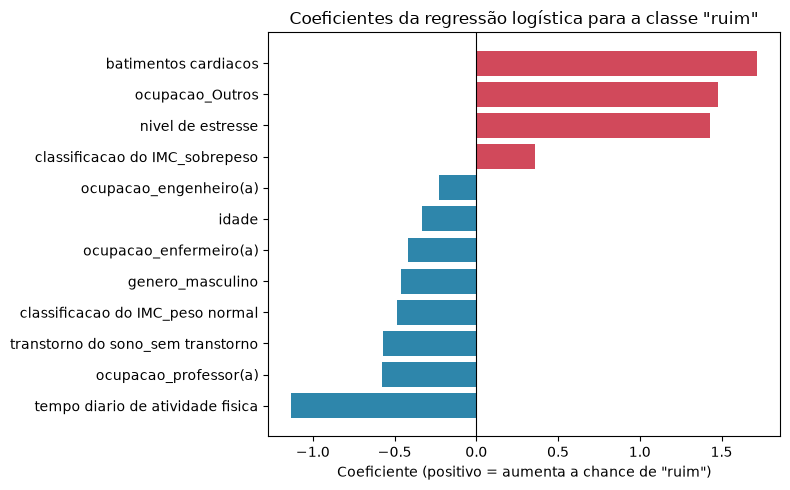

In [76]:
import pandas as pd
import matplotlib.pyplot as plt

nomes = melhor.named_steps["prep"].get_feature_names_out()
nomes = [n.split("__", 1)[-1] for n in nomes]   # remove o prefixo "num__" / "cat__"
clf = melhor.named_steps["clf"]

coefs = pd.DataFrame(clf.coef_.T, index=nomes, columns=clf.classes_)

top = coefs["ruim"].sort_values(key=abs, ascending=False).head(12).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
cores = ["#d1495b" if v > 0 else "#2e86ab" for v in top]
ax.barh(top.index, top.values, color=cores)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title('Coeficientes da regressão logística para a classe "ruim"')
ax.set_xlabel("Coeficiente (positivo = aumenta a chance de \"ruim\")")
plt.tight_layout()
plt.show()

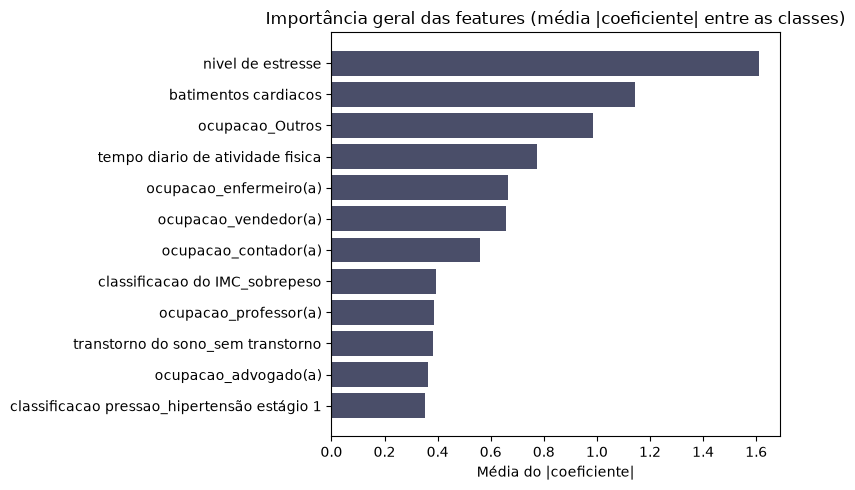

In [77]:
geral = coefs.abs().mean(axis=1).sort_values().tail(12)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(geral.index, geral.values, color="#4a4e69")
ax.set_title("Importância geral das features (média |coeficiente| entre as classes)")
ax.set_xlabel("Média do |coeficiente|")
plt.tight_layout()
plt.show()

In [63]:
df.to_csv('../processed/qualidade_do_sono_ML.csv')